In [1]:
import numpy as np
from experiments_utils import ICS26_DIR
from src.surrogate import HATANNSurrogate
from src.problems.lorenz96_flowmap import lorenz96_flowmap, lorenz96_flowmap_grad
from pathlib import Path
from ics26_experiments import (
    get_N_TRAIN,
    get_N_INIT_CLUSTERS,
    get_N_MIN_PER_CLUSTER
)

# Parameters for surrogate training (from train)
DIM = 5
TOL = 0.02
ERROR_METRIC = 'Linf-global'
DOMAIN = [-5.0, 5.0]
SEED = 0
FORCING = 1
DT = 0.1
N_TRAIN = get_N_TRAIN(DIM)
N_TIMESTEPS = 20
N_INIT_CLUSTERS = get_N_INIT_CLUSTERS(DIM)
N_MIN_PER_CLUSTER = get_N_MIN_PER_CLUSTER(DIM)


def f(x, output_var: int):
    f = lorenz96_flowmap(x, FORCING, DT)  # (N, d) vector
    N, d = f.shape
    return f[:, output_var].reshape((N, 1))

def f_full(x):
    return lorenz96_flowmap(x, FORCING, DT)  # (N, d) vector

def grad_f(x, output_var: int):
    g = lorenz96_flowmap_grad(x, FORCING, DT)
    N, d, _ = g.shape
    return g[:, output_var, :].reshape((N, 1, d))

def grad_f_full(x):
    return lorenz96_flowmap_grad(x, FORCING, DT)


/Users/blongaker/Documents/School Stuff/Research/knnsur/src/__init__.py:18: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [2]:
# Parameters for testing and building plot
TF = 5.0
tvec = np.arange(0, TF+DT, DT)
NSTEPS = int(TF / DT)

# Load data
surrogates = [HATANNSurrogate(version='v2') for _ in range(DIM)]
for i in range(DIM):
    lorenz_path = Path.cwd() / 'lorenz_surrogates'
    model_path = lorenz_path / f"lorenz96_dim{DIM}_F{FORCING}_tol{TOL}_tf{DT}_outputvar_{i}.npz"
    surrogates[i].train(
        X_train=None,
        f_fn=lambda x: f(x, i),
        g_fn=lambda x: grad_f(x, i),
        TOL=TOL,
        ERROR_METRIC=ERROR_METRIC,
        NUM_INITIAL_CLUSTERS=N_INIT_CLUSTERS,
        MIN_PTS_PER_CLUSTER=N_MIN_PER_CLUSTER,
        MAX_CLUSTERS_EST=20_000,
        SEED=SEED,
        USE_HESSIAN_INFORMED_SPLIT=True,
        IGNORE_GRADIENT=False,
        save_model=model_path,
        load_if_exists=True
    )


In [8]:
# Pick an initial point
# x0 = np.array(np.linspace(-3, 3, DIM))
np.random.seed(0)
x0 = np.random.randn(DIM) + FORCING

# Perturb initial point
eps = 1e-2
x0_pert = x0 + eps * np.random.randn(DIM)

# True solution
from src.problems.lorenz96 import lorenz96
from scipy.integrate import solve_ivp
def lorenz_rhs(t, x:np.ndarray):
    return lorenz96(x.reshape(1,DIM), forcing=FORCING).flatten()
struct_exact = solve_ivp(lorenz_rhs, [0, TF], x0, 'RK45', rtol=1e-6, t_eval=tvec)
struct_pert = solve_ivp(lorenz_rhs, [0, TF], x0_pert, 'RK45', rtol=1e-6, t_eval=tvec)

# Surrogate solution
surr = np.empty(shape=(DIM, NSTEPS+1))
surr[:,0] = x0
for j in range(NSTEPS):
    for k, surrogate in enumerate(surrogates):
        pred, _ = surrogate.predict(surr[:,j].reshape(1,DIM), k_nn=1)
        surr[k,j+1] = pred.flatten()

true = struct_exact.y
curr_perturbed = struct_pert.y


/var/folders/pc/_rlr7wmn33s7hb9l9kpgsj3w0000gn/T/ipykernel_92360/891563665.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  surr[k,j+1] = pred.flatten()


<>:65: SyntaxWarning: invalid escape sequence '\e'
<>:65: SyntaxWarning: invalid escape sequence '\e'
/var/folders/pc/_rlr7wmn33s7hb9l9kpgsj3w0000gn/T/ipykernel_92360/282763581.py:65: SyntaxWarning: invalid escape sequence '\e'
  label=f"Perturbed ($\epsilon={eps}$)",


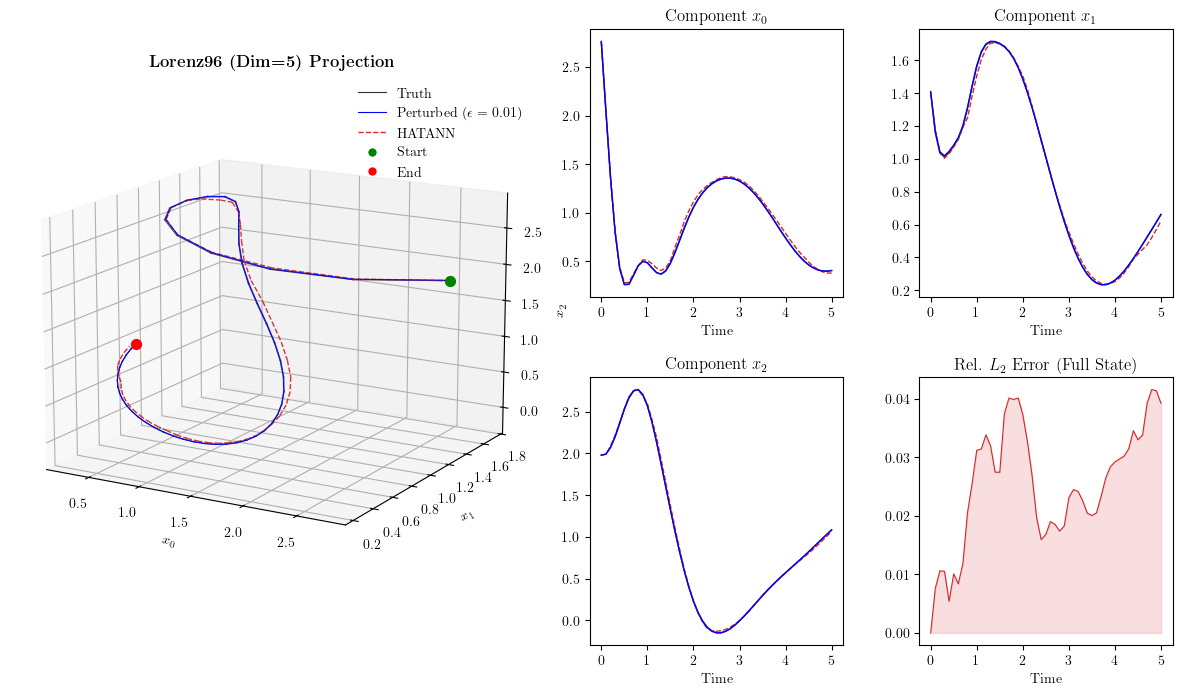

In [9]:
# Prajwal's plot code
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# Plotting
plt.rcParams.update(
    {"text.usetex": True, "font.family": "serif", "figure.figsize": (15, 8)}
)
fig = plt.figure()
gs = GridSpec(1, 2, width_ratios=[0.9, 1], wspace=0.1)

# 3D Phase Space (First 3 components)
ax3d = fig.add_subplot(gs[0], projection="3d")

n_points = true.shape[1]
alphas = np.linspace(0.9, 1.0, n_points)
for i in range(n_points - 1):
    # Truth
    ax3d.plot(
        true[0, i : i + 2],
        true[1, i : i + 2],
        true[2, i : i + 2],
        color="#333333",
        lw=0.8,
        alpha=alphas[i],
    )
    # Surrogate
    ax3d.plot(
        surr[0, i : i + 2],
        surr[1, i : i + 2],
        surr[2, i : i + 2],
        color="#d62728",
        ls="--",
        lw=1.0,
        alpha=alphas[i],
    )
    # Perturbed
    ax3d.plot(
        curr_perturbed[0, i : i + 2],
        curr_perturbed[1, i : i + 2],
        curr_perturbed[2, i : i + 2],
        color="blue",
        ls="-",
        lw=0.8,
        alpha=alphas[i],
    )

ax3d.scatter(true[0, 0], true[1, 0], true[2, 0], color="green", s=50, label="Start")
ax3d.scatter(true[0, -1], true[1, -1], true[2, -1], color="red", s=50, label="End")
ax3d.view_init(elev=15, azim=-60)
ax3d.set_title(rf"\textbf{{Lorenz96 (Dim={DIM}) Projection}}")
ax3d.set_xlabel("$x_0$")
ax3d.set_ylabel("$x_1$")
ax3d.set_zlabel("$x_2$")

legend_elements = [
    Line2D([0], [0], color="#333333", lw=0.8, label="Truth"),
    Line2D(
        [0],
        [0],
        color="blue",
        ls="-",
        lw=0.8,
        label=f"Perturbed ($\epsilon={eps}$)",
    ),
    Line2D([0], [0], color="#d62728", ls="--", lw=1.0, label="HATANN"),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="green",
        markersize=7,
        label="Start",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="red",
        markersize=7,
        label="End",
    ),
]
ax3d.legend(handles=legend_elements, frameon=False, loc="upper right")

# Components and Error
gs_sub = gs[1].subgridspec(2, 2, hspace=0.3, wspace=0.3)
labels = ["x_0", "x_1", "x_2"]

# Plot only first 3 components
for i in range(3):
    ax = fig.add_subplot(gs_sub[i // 2, i % 2])
    ax.plot(tvec, true[i], color="#333333", lw=1)
    ax.plot(tvec, surr[i], color="#d62728", ls="--", lw=1)
    ax.plot(tvec, curr_perturbed[i], color="blue", ls="-", lw=1)
    ax.set_title(f"Component ${labels[i]}$")
    ax.set_xlabel("Time")

# Error Plot
ax_err = fig.add_subplot(gs_sub[1, 1])
err = np.linalg.norm(true - surr, axis=0) / (np.linalg.norm(true, axis=0) + 1e-10)
ax_err.fill_between(tvec, err, color="#d62728", alpha=0.15)
ax_err.plot(tvec, err, color="#d62728", lw=0.8)
ax_err.set_title(r"Rel. $L_2$ Error (Full State)")
ax_err.set_xlabel("Time")

# print(f"ODE Integration Time: {_time_ode:.4f} seconds")
# print(f"Surrogate Prediction Time: {_time_sur:.4f} seconds")
# print(f"Speedup: {_time_ode / _time_sur:.2f}x (Steps: {STEPS:,})")
plt.show()
